In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [ ]:
# Traffic and simulation settings
SIMULATION_SLOTS = 10000
TRAFFIC_RATE = 0.8       # Mean packet arrivals per time slot
MAX_LINES = 10
MAX_SPACING = 10

# Objective function weights
W_LOSS = 0.6
W_DELAY = 0.3
W_COST = 0.1

# Generate one fixed traffic trace for fair comparisons
rng = np.random.default_rng(42)
arrivals = rng.poisson(TRAFFIC_RATE, SIMULATION_SLOTS)

print("Simulation slots:", SIMULATION_SLOTS)
print("Total arriving packets:", arrivals.sum())
print("Mean arrivals per slot:", arrivals.mean())

Simulation slots: 10000
Total arriving packets: 8030
Mean arrivals per slot: 0.803


In [ ]:
def simulate_optical_buffer(B, delta, arrivals):
    """
    Simplified fiber-delay-line buffer model.

    B     : number of delay lines
    delta : delay spacing in time slots
    """

    B = int(np.clip(round(B), 1, MAX_LINES))
    delta = int(np.clip(round(delta), 1, MAX_SPACING))

    # Delay of each line: delta, 2*delta, ..., B*delta
    delays = delta * np.arange(1, B + 1)

    # Time at which each line becomes available again
    free_at = np.zeros(B, dtype=int)

    accepted = 0
    dropped = 0
    total_delay = 0

    for t, number_of_arrivals in enumerate(arrivals):

        # Process each packet arriving in the current slot
        for _ in range(number_of_arrivals):

            # Find lines that are available now
            available = np.where(free_at <= t)[0]

            if len(available) == 0:
                dropped += 1
                continue

            # Choose the available line with the shortest delay
            line = available[np.argmin(delays[available])]

            # Schedule the packet's departure
            free_at[line] = t + delays[line]

            accepted += 1
            total_delay += delays[line]

    total_packets = accepted + dropped

    packet_loss = dropped / max(total_packets, 1)
    average_delay = total_delay / max(accepted, 1)

    return {
        "packet_loss": packet_loss,
        "average_delay": average_delay,
        "accepted": accepted,
        "dropped": dropped,
        "total_packets": total_packets,
        "B": B,
        "delta": delta
    }

In [ ]:
def objective_function(x):
    B = int(np.clip(round(x[0]), 1, MAX_LINES))
    delta = int(np.clip(round(x[1]), 1, MAX_SPACING))

    result = simulate_optical_buffer(B, delta, arrivals)

    # Normalize delay using the maximum possible configured delay
    max_delay = MAX_LINES * MAX_SPACING
    normalized_delay = result["average_delay"] / max_delay

    # Normalized hardware cost proxy
    normalized_cost = B / MAX_LINES

    fitness = (
        W_LOSS * result["packet_loss"]
        + W_DELAY * normalized_delay
        + W_COST * normalized_cost
    )

    return fitness

In [ ]:
def gwo(objective, population_size=25, iterations=100, seed=7):

    rng = np.random.default_rng(seed)

    lower = np.array([1.0, 1.0])
    upper = np.array([float(MAX_LINES), float(MAX_SPACING)])

    # Initialize candidate designs
    wolves = rng.uniform(
        lower, upper, size=(population_size, 2)
    )

    best_curve = []

    for t in range(iterations):

        # Evaluate current population
        fitness = np.array([objective(w) for w in wolves])

        # Rank wolves: alpha, beta, delta
        order = np.argsort(fitness)

        alpha = wolves[order[0]].copy()
        beta = wolves[order[1]].copy()
        delta = wolves[order[2]].copy()

        alpha_score = fitness[order[0]]
        best_curve.append(alpha_score)

        # Exploration/exploitation control
        a = 2 - 2 * t / max(iterations - 1, 1)

        new_wolves = np.zeros_like(wolves)

        for i, X in enumerate(wolves):

            candidates = []

            for leader in (alpha, beta, delta):
                r1 = rng.random(2)
                r2 = rng.random(2)

                A = 2 * a * r1 - a
                C = 2 * r2

                D = np.abs(C * leader - X)
                X_new = leader - A * D

                candidates.append(X_new)

            new_wolves[i] = np.mean(candidates, axis=0)

        # Enforce bounds
        wolves = np.clip(new_wolves, lower, upper)

    # Evaluate final population
    fitness = np.array([objective(w) for w in wolves])
    idx = np.argmin(fitness)

    final_best = wolves[idx].copy()
    final_score = fitness[idx]

    # Retain the best score observed across all iterations
    best_curve.append(final_score)

    return final_best, final_score, best_curve

In [ ]:
best_position, best_fitness, convergence = gwo(
    objective=objective_function,
    population_size=25,
    iterations=100,
    seed=7
)

optimal_B = int(np.clip(round(best_position[0]), 1, MAX_LINES))
optimal_delta = int(
    np.clip(round(best_position[1]), 1, MAX_SPACING)
)

result = simulate_optical_buffer(
    optimal_B, optimal_delta, arrivals
)

print("OPTIMIZED OPTICAL BUFFER")
print("-" * 35)
print("Optimal number of delay lines:", optimal_B)
print("Optimal delay spacing:", optimal_delta)
print("Best objective value:", round(best_fitness, 6))
print("Packet loss probability:", round(result["packet_loss"], 6))
print("Average delay (slots):", round(result["average_delay"], 3))
print("Packets accepted:", result["accepted"])
print("Packets dropped:", result["dropped"])

OPTIMIZED OPTICAL BUFFER
-----------------------------------
Optimal number of delay lines: 4
Optimal delay spacing: 1
Best objective value: 0.052491
Packet loss probability: 0.013699
Average delay (slots): 1.424
Packets accepted: 7920
Packets dropped: 110


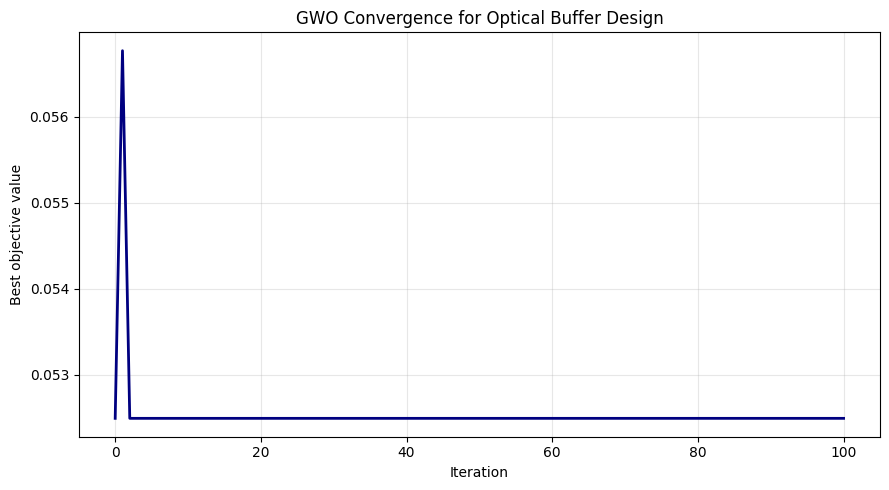

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(convergence, color="navy", linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Best objective value")
plt.title("GWO Convergence for Optical Buffer Design")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
baseline = simulate_optical_buffer(5, 3, arrivals)

def print_metrics(label, metrics):
    print(f"\n{label}")
    print("-" * 35)
    print(f"Number of delay lines: {metrics['B']}")
    print(f"Delay spacing: {metrics['delta']}")
    print(f"Packet loss: {metrics['packet_loss']:.6f}")
    print(f"Average delay: {metrics['average_delay']:.3f} slots")
    print(f"Accepted packets: {metrics['accepted']}")
    print(f"Dropped packets: {metrics['dropped']}")

print_metrics("Baseline configuration", baseline)
print_metrics("GWO configuration", result)


Baseline configuration
-----------------------------------
Number of delay lines: 5
Delay spacing: 3
Packet loss: 0.265131
Average delay: 6.491 slots
Accepted packets: 5901
Dropped packets: 2129

GWO configuration
-----------------------------------
Number of delay lines: 4
Delay spacing: 1
Packet loss: 0.013699
Average delay: 1.424 slots
Accepted packets: 7920
Dropped packets: 110


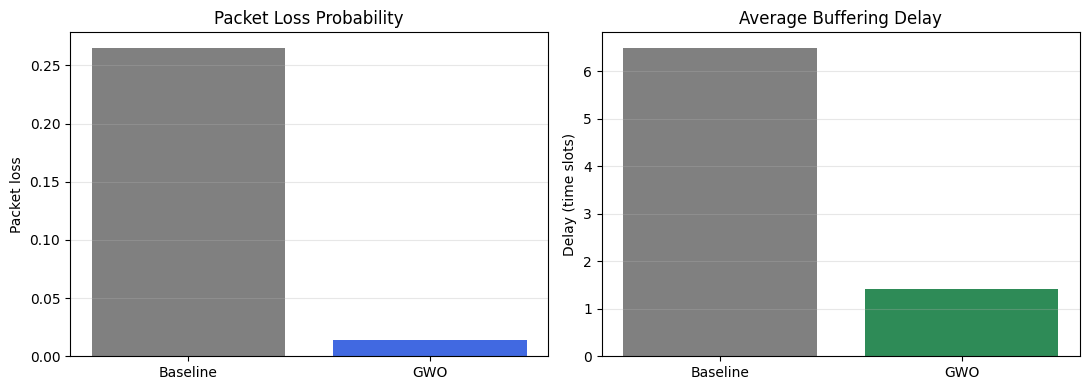

In [ ]:
labels = ["Baseline", "GWO"]
loss_values = [
    baseline["packet_loss"],
    result["packet_loss"]
]
delay_values = [
    baseline["average_delay"],
    result["average_delay"]
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(labels, loss_values, color=["gray", "royalblue"])
axes[0].set_title("Packet Loss Probability")
axes[0].set_ylabel("Packet loss")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(labels, delay_values, color=["gray", "seagreen"])
axes[1].set_title("Average Buffering Delay")
axes[1].set_ylabel("Delay (time slots)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()